In [1]:
import rasterio
from rasterio.mask import mask
from rasterio.plot import show
import geopandas as gpd
from shapely.geometry import Polygon

dataset = rasterio.open("sample-data/sample_raster.tif")

shape = Polygon([
    (160000, 2680000),
    (260000, 2660000),
    (300000, 2740000),
    (230000, 2790000),
    (150000, 2750000),
])

area = gpd.GeoDataFrame(geometry=[shape], crs=dataset.crs)

print(area.total_bounds)
print(dataset.bounds)

[ 150000. 2660000.  300000. 2790000.]
BoundingBox(left=101985.0, bottom=2611485.0, right=339315.0, top=2826915.0)


In [2]:
clipped, clipped_transform = mask(dataset, area.geometry, crop=True)
print(clipped.shape)

(3, 434, 500)


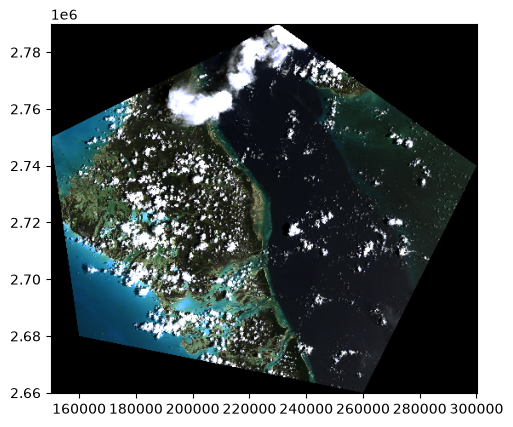

<Axes: >

In [3]:
show(clipped, transform=clipped_transform)

In [4]:
with rasterio.open(
    "sample-data/clipped_by_shape.tif",
    "w",
    driver="GTiff",
    height=clipped.shape[1],
    width=clipped.shape[2],
    count=3,
    dtype=clipped.dtype,
    crs=dataset.crs,
    transform=clipped_transform,
) as new_file:
    new_file.write(clipped)

print("saved")

saved


1 EPSG:4326


<Axes: >

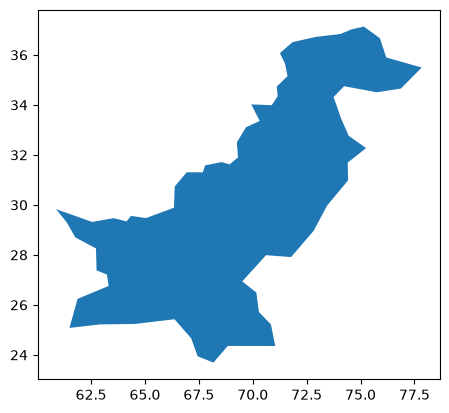

In [5]:
import geopandas as gpd

countries = gpd.read_file("sample-data/ne_110m_admin_0_countries.shp")
pakistan = countries[countries["NAME"] == "Pakistan"]
print(len(pakistan), pakistan.crs)
pakistan.plot()

In [1]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.plot import show

countries = gpd.read_file("sample-data/ne_110m_admin_0_countries.shp")
pakistan = countries[countries["NAME"] == "Pakistan"]

world = rasterio.open("sample-data/NE1_50M_SR_W.tif")
print(world.crs, world.count, world.width, world.height)
print(world.bounds)

RasterioIOError: sample-data/NE1_50M_SR_W.tif: No such file or directory

In [2]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.plot import show

countries = gpd.read_file("sample-data/ne_110m_admin_0_countries.shp")
pakistan = countries[countries["NAME"] == "Pakistan"]

world = rasterio.open("sample-data/NE1_50M_SR_W.tif")
print(world.crs, world.count, world.width, world.height)
print(world.bounds)

EPSG:4326 3 10800 5400
BoundingBox(left=-179.99999999999997, bottom=-89.99999999998201, right=179.99999999996405, top=90.0)


(3, 404, 510)


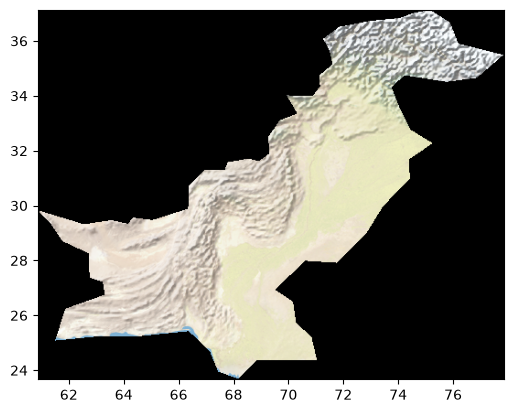

<Axes: >

In [3]:
clipped, clipped_transform = mask(world, pakistan.geometry, crop=True)
print(clipped.shape)
show(clipped, transform=clipped_transform)

In [4]:
with rasterio.open(
    "sample-data/pakistan_relief.tif",
    "w",
    driver="GTiff",
    height=clipped.shape[1],
    width=clipped.shape[2],
    count=3,
    dtype=clipped.dtype,
    crs=world.crs,
    transform=clipped_transform,
) as new_file:
    new_file.write(clipped)

print("saved")

saved


In [5]:
saved = rasterio.open("sample-data/pakistan_relief.tif")
print(saved.crs)
print(saved.bounds)

EPSG:4326
BoundingBox(left=60.86666666664263, bottom=23.6666666666733, right=77.86666666664092, top=37.13333333333862)


In [6]:
git add .

SyntaxError: invalid syntax (3827820173.py, line 1)

In [1]:
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   .ipynb_checkpoints/day6_raster_crop-checkpoint.ipynb
	new file:   .ipynb_checkpoints/day7_raster_clip-checkpoint.ipynb
	new file:   day6_raster_crop.ipynb
	new file:   day7_raster_clip.ipynb
	new file:   sample-data/NE1_50M_SR_W.tfw
	new file:   sample-data/NE1_50M_SR_W.tif
	new file:   sample-data/clipped_by_shape.tif
	new file:   sample-data/cropped_with_location.tif
	new file:   sample-data/pakistan_relief.tif

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   day7_raster_clip.ipynb



In [2]:
!git restore --staged .

In [3]:
%%writefile .gitignore
sample-data/NE1_50M_SR_W.tif
sample-data/NE1_50M_SR_W.tfw
.ipynb_checkpoints/

Writing .gitignore


In [4]:
!git add .
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   .gitignore
	new file:   day6_raster_crop.ipynb
	new file:   day7_raster_clip.ipynb
	new file:   sample-data/clipped_by_shape.tif
	new file:   sample-data/cropped_with_location.tif
	new file:   sample-data/pakistan_relief.tif



In [5]:
!git commit -m "Add day 6 and 7 raster notebooks"
!git push

[main 93feb7b] Add day 6 and 7 raster notebooks
 6 files changed, 491 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 day6_raster_crop.ipynb
 create mode 100644 day7_raster_clip.ipynb
 create mode 100644 sample-data/clipped_by_shape.tif
 create mode 100644 sample-data/cropped_with_location.tif
 create mode 100644 sample-data/pakistan_relief.tif


To https://github.com/devayesha23/gis-fullstack-roadmap.git
   2aa2518..93feb7b  main -> main
